<a href="https://colab.research.google.com/github/naserhusovic-droid/dsb_capston/blob/main/Finall_01_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**CAPSTONE PROJECT "IIrregular Migration Across the Western Balkan Route, impact on Montenegro and prediction of the number of illegals by month in 2027"**

**1. IMPORT LIBRARIES**

**I imported the libraries needed for manipulation, statistical analysis, visualization and Machine Learning.**

In [5]:
# I find the Data, check and find which libraries I need to import for my CAPSTONE
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from itertools import product
from sklearn.linear_model import LinearRegression, LassoCV, RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.cluster import KMeans
from sklearn.metrics import r2_score

**2. LOAD EXCEL DATA**

In [6]:
# I import and read my first exel datasets,
# which have 9 but I will fokus on 5 main sheets
im1 = pd.read_excel('/content/DTM Europe_Q1_2026_Dataset.xlsx')

Out of 9 sheets I will use 5. The other 4 ('About',
 'Summary', 'Sources','ISO3') is related to the description of the dataset and does not contain data related to migrations / migrants. My dataset, has a total of 2,780 rows in 5 sheets.

**3. DATA MANIPULATION — data structure check, cleaning and preparation**

In [7]:
xls1 = pd.ExcelFile('/content/DTM Europe_Q1_2026_Dataset.xlsx')
xls1.sheet_names


['About',
 'Summary',
 'First_Arrival_Countries_Monthly',
 'Other_Countries_Areas_Monthly',
 'First_Arrival_Countries_CoO',
 'Others_Countries_CoO',
 'All_Migrant_Presence',
 'Sources',
 'ISO3']

In [8]:
file_path = '/content/DTM Europe_Q1_2026_Dataset.xlsx'

In [9]:
# These are the sheets name from the data sets, which I will use when answering the data question.

selected_sheets = ['First_Arrival_Countries_Monthly',
 'Other_Countries_Areas_Monthly',
 'First_Arrival_Countries_CoO',
 'Others_Countries_CoO',
 'All_Migrant_Presence']

datasets = {
    sheet: pd.read_excel(file_path, sheet_name=sheet)
    for sheet in selected_sheets
}

In [10]:
for i, sheet in enumerate(xls1.sheet_names, start=1):
    globals()['im_%s' % str(i)] = pd.read_excel(
        '/content/DTM Europe_Q1_2026_Dataset.xlsx',
        sheet_name=sheet
    )

In [11]:
#  Geting familiarization with data sets, reading all sheets
#  and naming each sheet separately, for easy use in the continuation of the capstone

im1_1 = datasets['First_Arrival_Countries_Monthly']
im1_2 = datasets['Other_Countries_Areas_Monthly']
im1_3 = datasets['First_Arrival_Countries_CoO']
im1_4 = datasets['Others_Countries_CoO']
im1_5 = datasets['All_Migrant_Presence']

for name, im1 in datasets.items():
    print(f"\n{'=' * 65}")
    print(f"DATASET: {name}")
    print(f"Shape: {im1.shape}")
    print("\nColumns:")
    print(im1.columns.tolist())
    print("\nData types and non-null values:")
    im1.info()
    print("\nMissing values:")
    print(im1.isnull().sum())
    print("\nFirst 3 rows:")
    display(im1.head())


DATASET: First_Arrival_Countries_Monthly
Shape: (1128, 7)

Columns:
['Date', 'Year', 'Month', 'ISO3 - Country of arrival', 'Route', 'Type of arrival', 'Arrivals']

Data types and non-null values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1128 entries, 0 to 1127
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Date                       1128 non-null   datetime64[ns]
 1   Year                       1128 non-null   int64         
 2   Month                      1128 non-null   int64         
 3   ISO3 - Country of arrival  1128 non-null   object        
 4   Route                      1128 non-null   object        
 5   Type of arrival            1128 non-null   object        
 6   Arrivals                   1128 non-null   int64         
dtypes: datetime64[ns](1), int64(3), object(3)
memory usage: 61.8+ KB

Missing values:
Date                         0
Year        

,Date,Year,Month,ISO3 - Country of arrival,Route,Type of arrival,Arrivals
0,2016-01-31,2016,1,BGR,EMR,Land,596
1,2017-01-31,2017,1,BGR,EMR,Land,48
2,2018-01-31,2018,1,BGR,EMR,Land,116
3,2019-01-31,2019,1,BGR,EMR,Land,80
4,2020-01-31,2020,1,BGR,EMR,Land,75



DATASET: Other_Countries_Areas_Monthly
Shape: (1066, 7)

Columns:
['Date', 'Year', 'Month', 'ISO3 - Country of arrival', 'Route', 'Type of arrival', 'Arrivals']

Data types and non-null values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1066 entries, 0 to 1065
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Date                       1066 non-null   datetime64[ns]
 1   Year                       1066 non-null   int64         
 2   Month                      1066 non-null   int64         
 3   ISO3 - Country of arrival  1066 non-null   object        
 4   Route                      1066 non-null   object        
 5   Type of arrival            1066 non-null   object        
 6   Arrivals                   1066 non-null   int64         
dtypes: datetime64[ns](1), int64(3), object(3)
memory usage: 58.4+ KB

Missing values:
Date                         0
Year          

,Date,Year,Month,ISO3 - Country of arrival,Route,Type of arrival,Arrivals
0,2016-01-31,2016,1,ALB,WBR,Land,55
1,2017-01-31,2017,1,ALB,WBR,Land,108
2,2018-01-31,2018,1,ALB,WBR,Land,114
3,2019-01-31,2019,1,ALB,WBR,Land,59
4,2020-01-31,2020,1,ALB,WBR,Land,156



DATASET: First_Arrival_Countries_CoO
Shape: (330, 8)

Columns:
['Date', 'Year', 'Month', 'ISO3 - Country of origin', 'ISO3 - Country of arrival', 'Route', 'Arrivals', 'Source']

Data types and non-null values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 330 entries, 0 to 329
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Date                       330 non-null    datetime64[ns]
 1   Year                       330 non-null    int64         
 2   Month                      330 non-null    int64         
 3   ISO3 - Country of origin   330 non-null    object        
 4   ISO3 - Country of arrival  330 non-null    object        
 5   Route                      330 non-null    object        
 6   Arrivals                   330 non-null    int64         
 7   Source                     330 non-null    object        
dtypes: datetime64[ns](1), int64(3), object(4)
memory u

,Date,Year,Month,ISO3 - Country of origin,ISO3 - Country of arrival,Route,Arrivals,Source
0,2026-01-31,2026,1,SLE,MLT,CMR,1,"Maltese Minitry of Home Affairs, Security and ..."
1,2026-01-31,2026,1,BFA,ITA,CMR,2,Italian Ministry of the Interior
2,2026-01-31,2026,1,BGD,ITA,CMR,497,Italian Ministry of the Interior
3,2026-01-31,2026,1,CIV,ITA,CMR,40,Italian Ministry of the Interior
4,2026-01-31,2026,1,CMR,ITA,CMR,19,Italian Ministry of the Interior



DATASET: Others_Countries_CoO
Shape: (439, 8)

Columns:
['Date', 'Year', 'Month', 'ISO3 - Country of origin', 'ISO3 - Country of arrival', 'Route', 'Arrivals', 'Source']

Data types and non-null values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 439 entries, 0 to 438
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Date                       439 non-null    datetime64[ns]
 1   Year                       439 non-null    int64         
 2   Month                      439 non-null    int64         
 3   ISO3 - Country of origin   439 non-null    object        
 4   ISO3 - Country of arrival  439 non-null    object        
 5   Route                      439 non-null    object        
 6   Arrivals                   439 non-null    int64         
 7   Source                     439 non-null    object        
dtypes: datetime64[ns](1), int64(3), object(4)
memory usage: 2

,Date,Year,Month,ISO3 - Country of origin,ISO3 - Country of arrival,Route,Arrivals,Source
0,2026-01-31,2026,1,AFG,XKX,WBR,1,"Kosovo* Ministry of Internal Affairs, Border P..."
1,2026-01-31,2026,1,DZA,XKX,WBR,21,"Kosovo* Ministry of Internal Affairs, Border P..."
2,2026-01-31,2026,1,EGY,XKX,WBR,15,"Kosovo* Ministry of Internal Affairs, Border P..."
3,2026-01-31,2026,1,JOR,XKX,WBR,1,"Kosovo* Ministry of Internal Affairs, Border P..."
4,2026-01-31,2026,1,LBN,XKX,WBR,1,"Kosovo* Ministry of Internal Affairs, Border P..."



DATASET: All_Migrant_Presence
Shape: (147, 6)

Columns:
['Date', 'Year', 'Month', 'Week', 'ISO3 - Host country', 'Individuals present']

Data types and non-null values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 147 entries, 0 to 146
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Date                 147 non-null    datetime64[ns]
 1   Year                 147 non-null    int64         
 2   Month                147 non-null    int64         
 3   Week                 147 non-null    int64         
 4   ISO3 - Host country  147 non-null    object        
 5   Individuals present  147 non-null    int64         
dtypes: datetime64[ns](1), int64(4), object(1)
memory usage: 7.0+ KB

Missing values:
Date                   0
Year                   0
Month                  0
Week                   0
ISO3 - Host country    0
Individuals present    0
dtype: int64

First 3 rows:


,Date,Year,Month,Week,ISO3 - Host country,Individuals present
0,2026-01-04,2026,1,2,ALB,5
1,2026-01-11,2026,1,3,ALB,5
2,2026-01-18,2026,1,4,ALB,5
3,2026-01-25,2026,1,5,ALB,5
4,2026-02-01,2026,1,6,ALB,20


In [12]:
# Checking for missing values ​​and checking for duplicates.
for name, data in datasets.items():

    print(f"\nDataset: {name}")

    print("Rows:", data.shape[0])
    print("Columns:", data.shape[1])

    print("Duplicate rows:", data.duplicated().sum())

    print("Missing values:", data.isna().sum().sum())


Dataset: First_Arrival_Countries_Monthly
Rows: 1128
Columns: 7
Duplicate rows: 0
Missing values: 0

Dataset: Other_Countries_Areas_Monthly
Rows: 1066
Columns: 7
Duplicate rows: 0
Missing values: 0

Dataset: First_Arrival_Countries_CoO
Rows: 330
Columns: 8
Duplicate rows: 0
Missing values: 0

Dataset: Others_Countries_CoO
Rows: 439
Columns: 8
Duplicate rows: 0
Missing values: 0

Dataset: All_Migrant_Presence
Rows: 147
Columns: 6
Duplicate rows: 0
Missing values: 0


In [13]:
im1_1['Date'] = pd.to_datetime(im1_1['Date'], errors='coerce')

print(im1_1['Date'].dtype)
print(im1_1['Date'].isna().sum())

datetime64[ns]
0


In [14]:
# check of each sheets in the datasets
for name, data in datasets.items():

    print(f"\nDATASET: {name}")

    for column in data.columns:

        if column.startswith("ISO3"):

            print(f"\nColumn: {column}")

            values = data[column].dropna().astype(str).unique()

            print("Montenegro present:", "MNE" in values)
            print("Number of unique values:", len(values))


DATASET: First_Arrival_Countries_Monthly

Column: ISO3 - Country of arrival
Montenegro present: False
Number of unique values: 6

DATASET: Other_Countries_Areas_Monthly

Column: ISO3 - Country of arrival
Montenegro present: True
Number of unique values: 9

DATASET: First_Arrival_Countries_CoO

Column: ISO3 - Country of origin
Montenegro present: False
Number of unique values: 54

Column: ISO3 - Country of arrival
Montenegro present: False
Number of unique values: 6

DATASET: Others_Countries_CoO

Column: ISO3 - Country of origin
Montenegro present: False
Number of unique values: 62

Column: ISO3 - Country of arrival
Montenegro present: True
Number of unique values: 8

DATASET: All_Migrant_Presence

Column: ISO3 - Host country
Montenegro present: True
Number of unique values: 12


In [15]:
# missing values

for name, data in datasets.items():

    missing = pd.DataFrame({
        'Missing values': data.isna().sum(),
        'Missing percentage': data.isna().mean() * 100
    })

    print(f"\n{name}")
    display(
        missing.sort_values(
            'Missing percentage',
            ascending=False
        )
    )


First_Arrival_Countries_Monthly


,Missing values,Missing percentage
Date,0,0.0
Year,0,0.0
Month,0,0.0
ISO3 - Country of arrival,0,0.0
Route,0,0.0
Type of arrival,0,0.0
Arrivals,0,0.0



Other_Countries_Areas_Monthly


,Missing values,Missing percentage
Date,0,0.0
Year,0,0.0
Month,0,0.0
ISO3 - Country of arrival,0,0.0
Route,0,0.0
Type of arrival,0,0.0
Arrivals,0,0.0



First_Arrival_Countries_CoO


,Missing values,Missing percentage
Date,0,0.0
Year,0,0.0
Month,0,0.0
ISO3 - Country of origin,0,0.0
ISO3 - Country of arrival,0,0.0
Route,0,0.0
Arrivals,0,0.0
Source,0,0.0



Others_Countries_CoO


,Missing values,Missing percentage
Date,0,0.0
Year,0,0.0
Month,0,0.0
ISO3 - Country of origin,0,0.0
ISO3 - Country of arrival,0,0.0
Route,0,0.0
Arrivals,0,0.0
Source,0,0.0



All_Migrant_Presence


,Missing values,Missing percentage
Date,0,0.0
Year,0,0.0
Month,0,0.0
Week,0,0.0
ISO3 - Host country,0,0.0
Individuals present,0,0.0


**3. EDA MODELING**

The line plot shows changes in the number of recorded arrivals over time.

Use it to identify:
- periods of increased migration;
- reduction periods;
- sudden changes;
- long-term trends.

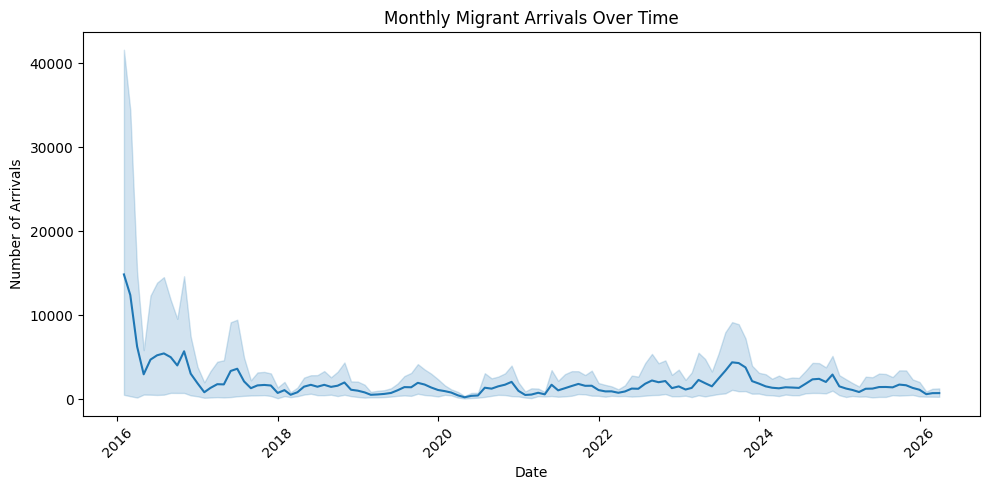

In [16]:
df = im1_1.copy()

df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

df = df.sort_values('Date')

plt.figure(figsize=(10, 5))
sns.lineplot(data=df, x='Date', y='Arrivals')

plt.title('Monthly Migrant Arrivals Over Time')
plt.xlabel('Date')
plt.ylabel('Number of Arrivals')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Here I have grouped and added the values ​​of Arrivals by year.

I got the annual number of recorded arrivals for comparison by year from 2016 to 2026.

In [17]:
# Sorting and grouping

yearly_migration = (
    df.groupby("Year", as_index=False)["Arrivals"]
    .sum()
    .sort_values("Year")
)

print(yearly_migration)

    Year  Arrivals
0   2016    389976
1   2017    187499
2   2018    146949
3   2019    128663
4   2020     99907
5   2021    151417
6   2022    189595
7   2023    293838
8   2024    208909
9   2025    158003
10  2026     19254


In [18]:
# Here I do with first column 'First_Arrival_Countries_Monthly' from my first dataset
# 'im1' - is for first datasets, '_1' is for first sheet.
im1_1 = pd.read_excel('/content/DTM Europe_Q1_2026_Dataset.xlsx', sheet_name= 'First_Arrival_Countries_Monthly')

In [19]:
im1_1.head()

,Date,Year,Month,ISO3 - Country of arrival,Route,Type of arrival,Arrivals
0,2016-01-31,2016,1,BGR,EMR,Land,596
1,2017-01-31,2017,1,BGR,EMR,Land,48
2,2018-01-31,2018,1,BGR,EMR,Land,116
3,2019-01-31,2019,1,BGR,EMR,Land,80
4,2020-01-31,2020,1,BGR,EMR,Land,75


In [20]:
im1_1['Date'] = pd.to_datetime(im1_1['Date'], errors='coerce')

print(im1_1['Date'].dtype)
print(im1_1['Date'].isna().sum())

datetime64[ns]
0


In [21]:
# Here, with the .unique() function, I wanted to check
# whether there is Montenegro in the column 'ISO3 - Country of arrival'
im1_1['ISO3 - Country of arrival'].unique()

array(['BGR', 'CYP', 'ESP', 'GRC', 'ITA', 'MLT'], dtype=object)

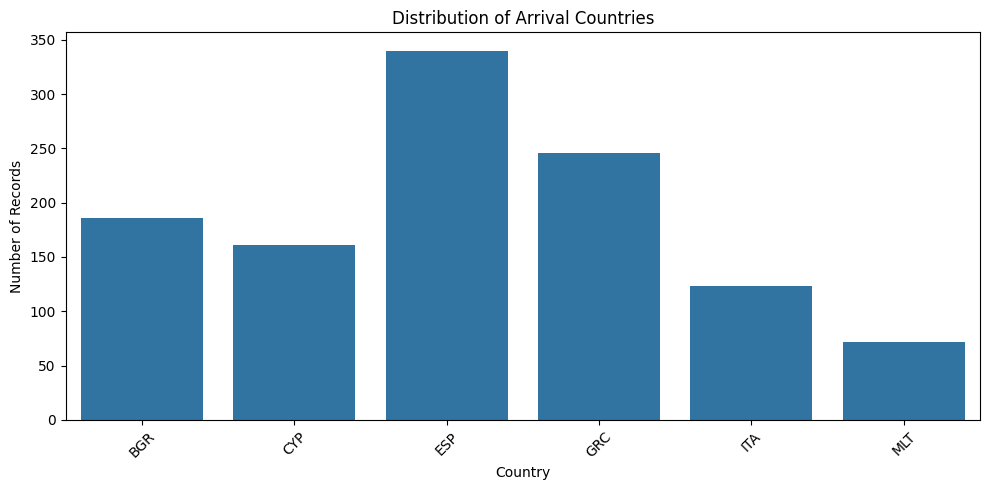

In [22]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=im1_1,
    x='ISO3 - Country of arrival'
)

plt.title('Distribution of Arrival Countries')
plt.xlabel('Country')
plt.ylabel('Number of Records')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

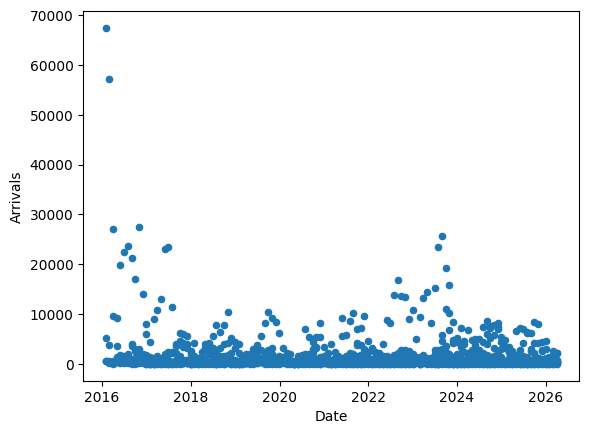

In [23]:
im1_1.plot(kind='scatter', x='Date', y='Arrivals');

In [24]:
# Here is presented the number of migrants who entered the territory of the EU
# via different routes in the first quarter of 2026.
print("First Arrival Routes:")
print(im1_1['Route'].value_counts(dropna=False))


First Arrival Routes:
Route
EMR     593
WMR     234
CMR     195
WAAR    106
Name: count, dtype: int64


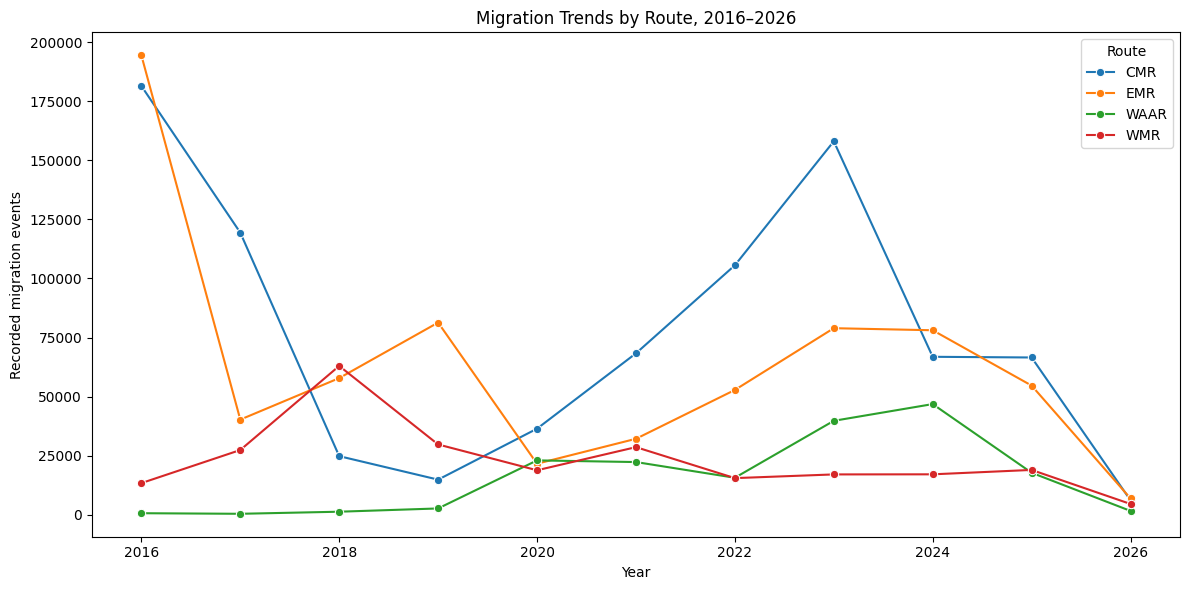

In [25]:
# In my data, im1_1['ISO3 - Country of arrival'], above I get names of the country
# which was on the migration route - ['BGR', 'CYP', 'ESP', 'GRC', 'ITA', 'MLT']
# Migrant routes: "Eastern Mediterranean Route = EMR", "Western African Atlantic Route = WAAR",
################# "Central Mediterranean Route = CMR", "Western Mediterranean Route = WMR".

route_comparison = (
    im1_1.groupby(["Year", "Route"], as_index=False)["Arrivals"]
    .sum()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=route_comparison,
    x="Year",
    y="Arrivals",
    hue="Route",
    marker="o"
)

plt.title("Migration Trends by Route, 2016–2026")
plt.xlabel("Year")
plt.ylabel("Recorded migration events")
plt.tight_layout()
plt.show()

In [26]:
im1_1.groupby(['Date','ISO3 - Country of arrival', 'Route'])['Arrivals'].sum()

Date        ISO3 - Country of arrival  Route
2016-01-31  BGR                        EMR        596
            ESP                        WMR        492
            GRC                        EMR      67954
            ITA                        CMR       5273
2016-02-29  BGR                        EMR        450
                                                ...  
2026-03-31  CYP                        EMR        154
            ESP                        WAAR       366
                                       WMR       1332
            GRC                        EMR       2474
            ITA                        CMR       2150
Name: Arrivals, Length: 781, dtype: int64

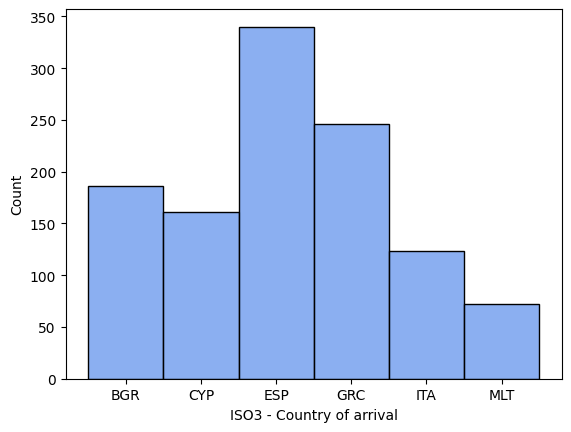

In [27]:
sns.histplot(im1_1['ISO3 - Country of arrival'], bins = 25, color = 'cornflowerblue', edgecolor = 'black');

In [67]:
# Here I do with second column 'Other_Countries_Areas_Monthly' from my first dataset
# 'im1' - is for first datasets, '_2' is for second column
# im1_2 = pd.read_excel('/content/DTM Europe_Q1_2026_Dataset.xlsx', sheet_name= 'Other_Countries_Areas_Monthly')

In [68]:
im1_2.head()

,Date,Year,Month,ISO3 - Country of arrival,Route,Type of arrival,Arrivals
0,2016-01-31,2016,1,ALB,WBR,Land,55
1,2017-01-31,2017,1,ALB,WBR,Land,108
2,2018-01-31,2018,1,ALB,WBR,Land,114
3,2019-01-31,2019,1,ALB,WBR,Land,59
4,2020-01-31,2020,1,ALB,WBR,Land,156


In [69]:
im1_2['Date'] = pd.to_datetime(im1_2['Date'], errors='coerce')

print(im1_2['Date'].dtype)
print(im1_2['Date'].isna().sum())

datetime64[ns]
0


In [70]:
# With the .unique() function, I checked the column 'ISO3 - Country of arrival'
# and found that among the listed countries there is Montenegro
im1_2['ISO3 - Country of arrival'].unique()

array(['ALB', 'BIH', 'HRV', 'MKD', 'MNE', 'ROU', 'SRB', 'SVN', 'XKX'],
      dtype=object)

In [71]:
pd.set_option('display.max_rows', None)

im1_2.groupby(['Date','ISO3 - Country of arrival', 'Route'])['Arrivals'].sum()

Date        ISO3 - Country of arrival  Route   
2016-01-31  ALB                        WBR            55
            HRV                        EU Other    65546
            MKD                        WBR         53436
            MNE                        WBR            81
            SRB                        WBR         58464
            SVN                        EU Other    62785
            XKX                        WBR            14
2016-02-29  ALB                        WBR            19
            HRV                        EU Other    35092
            MKD                        WBR         34404
            MNE                        WBR            15
            SRB                        WBR         36141
            SVN                        EU Other    34795
            XKX                        WBR             1
2016-03-31  ALB                        WBR            37
            HRV                        EU Other     1637
            MKD                        WBR          1783
            MNE                        WBR             3
            SRB                        WBR          1512
            SVN                        EU Other     1607
2016-04-30  ALB                        WBR            69
            MNE                        WBR             9
            SRB                        WBR            18
            XKX                        WBR             3
2016-05-31  ALB                        WBR           127
            MKD                        WBR            47
            MNE                        WBR             2
            SRB                        WBR           367
            XKX                        WBR            16
2016-06-30  ALB                        WBR            47
            MNE                        WBR             6
            SRB                        WBR           904
            XKX                        WBR            20
2016-07-31  ALB                        WBR            16
            MKD                        WBR            12
            MNE                        WBR             9
            SRB                        WBR           525
            XKX                        WBR            44
2016-08-31  ALB                        WBR           108
            MKD                        WBR             9
            MNE                        WBR            31
            SRB                        WBR           603
            XKX                        WBR            42
2016-09-30  ALB                        WBR           136
            MKD                        WBR             7
            MNE                        WBR             9
            SRB                        WBR           236
            XKX                        WBR            35
2016-10-31  ALB                        WBR            84
            MKD                        WBR            66
            MNE                        WBR            28
            SRB                        WBR            22
            XKX                        WBR            23
2016-11-30  ALB                        WBR            94
            MKD                        WBR             7
            MNE                        WBR            45
            SRB                        WBR           183
            XKX                        WBR            26
2016-12-31  ALB                        WBR            39
            MNE                        WBR            70
            XKX                        WBR            55
2017-01-31  ALB                        WBR           108
            BIH                        WBR            77
            HRV                        EU Other      225
            MKD                        WBR             2
            MNE                        WBR            41
            SRB                        WBR           333
            SVN                        EU Other       79
            XKX                        WBR            18
2017-02-28  ALB    

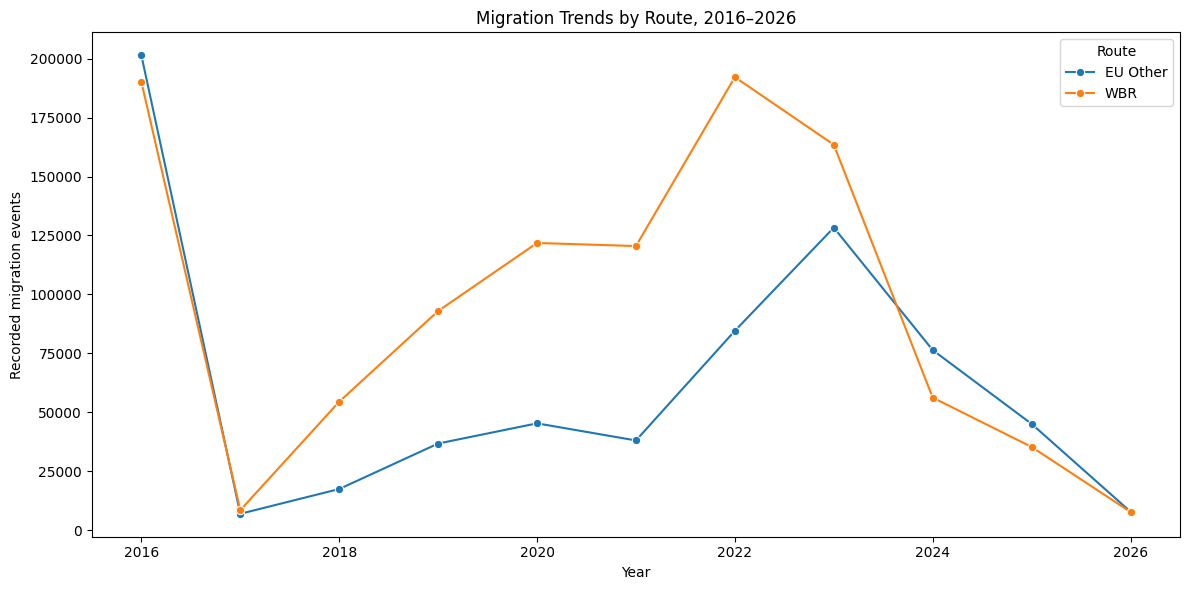

In [33]:
# Migrant routes: , "Westwrn Balkans Route", "EU Other".

route_comparison = (
    im1_2.groupby(["Year", "Route"], as_index=False)["Arrivals"]
    .sum()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=route_comparison,
    x="Year",
    y="Arrivals",
    hue="Route",
    marker="o"
)

plt.title("Migration Trends by Route, 2016–2026")
plt.xlabel("Year")
plt.ylabel("Recorded migration events")
plt.tight_layout()
plt.show()

In [34]:
# Here is presented the number of migraiants who entered Montenegro in the first quarter of 2026,
# via the WBR route and the EU other route
print("\nOther Countries/Areas Routes:")
print(im1_2['Route'].value_counts(dropna=False))


Other Countries/Areas Routes:
Route
WBR         724
EU Other    342
Name: count, dtype: int64


In [35]:
# TIME SERIES - Prepare a monthly time series
# Each line represents one month and the total number of recorded arrivals for that month.

western_balkan_route_name = 'WBR'

df_wb = im1_2.copy()

df_wb['Date'] = pd.to_datetime(
    df_wb['Date'],
    errors='coerce'
)

df_wb = df_wb.dropna(subset=['Date'])

df_wb = df_wb[
    df_wb['Route'] == western_balkan_route_name
].copy()

df_wb['Month'] = (
    df_wb['Date']
    .dt.to_period('M')
    .dt.to_timestamp()
)

wb_monthly = (
    df_wb.groupby('Month')['Arrivals']
    .sum()
    .sort_index()
)

print(wb_monthly.head())
print(wb_monthly.tail())
print("Number of months:", len(wb_monthly))

Month
2016-01-01    112050
2016-02-01     70580
2016-03-01      3335
2016-04-01        99
2016-05-01       559
Name: Arrivals, dtype: int64
Month
2025-11-01    3995
2025-12-01    2621
2026-01-01    1660
2026-02-01    2763
2026-03-01    3284
Name: Arrivals, dtype: int64
Number of months: 123


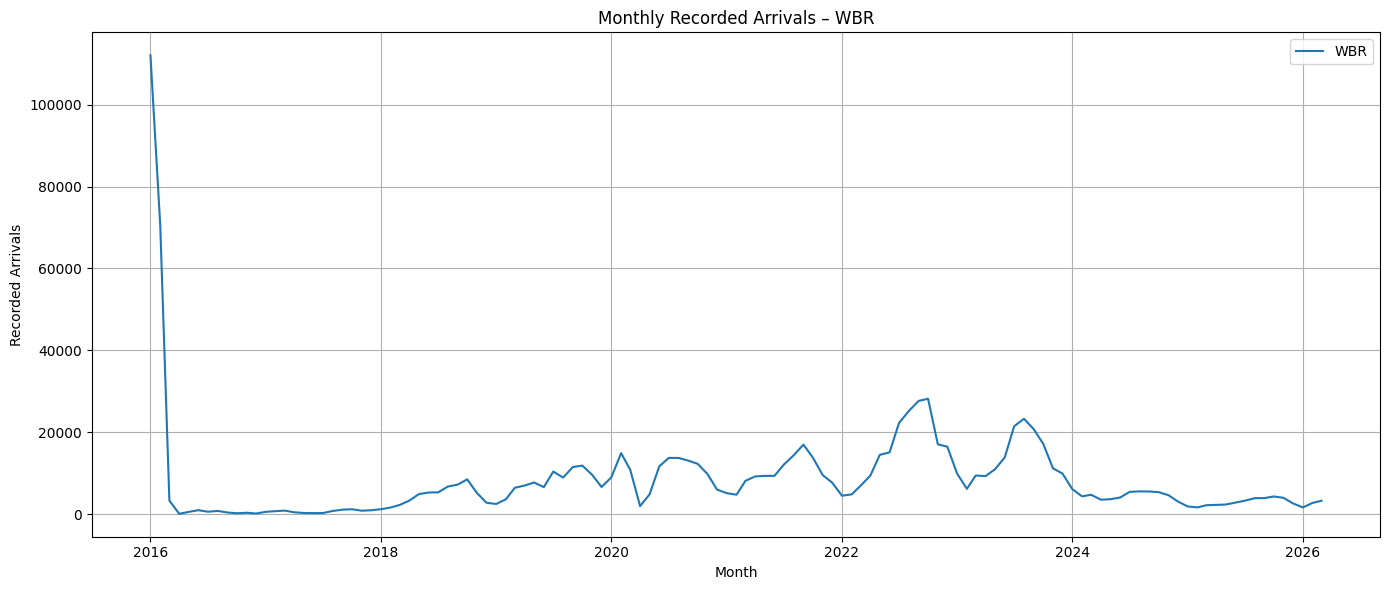

In [78]:
plt.figure(figsize=(14, 6))

plt.plot(
    wb_monthly.index,
    wb_monthly.values,
    label='WBR'
)

plt.title('Monthly Recorded Arrivals – WBR')
plt.xlabel('Month')
plt.ylabel('Recorded Arrivals')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

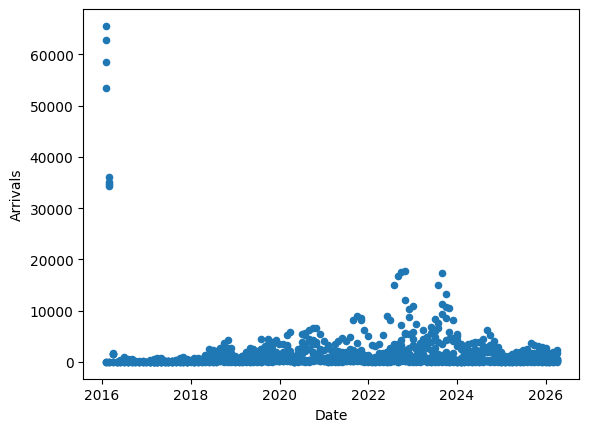

In [36]:
im1_2.plot(kind='scatter', x='Date', y='Arrivals');

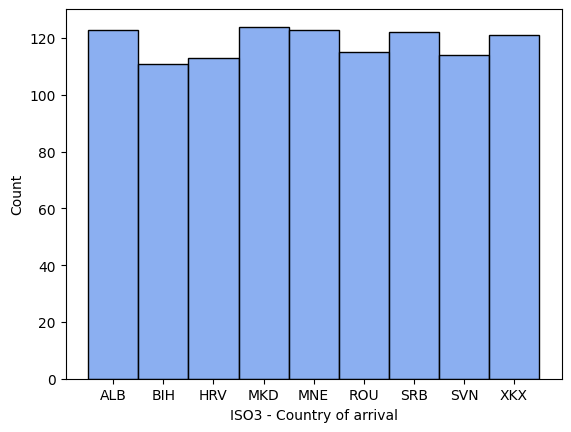

In [37]:
sns.histplot(im1_2['ISO3 - Country of arrival'], bins = 25, color = 'cornflowerblue', edgecolor = 'black');

In [38]:
# through this syntax, I extracted data related to the trend
# of illegal migration via the Balkan route (WBR) from 2020 to 2025

im1_2[im1_2['Year']>2020]

,Date,Year,Month,ISO3 - Country of arrival,Route,Type of arrival,Arrivals
5,2021-01-31,2021,1,ALB,WBR,Land,777
6,2022-01-31,2022,1,ALB,WBR,Land,255
7,2023-01-31,2023,1,ALB,WBR,Land,219
8,2024-01-31,2024,1,ALB,WBR,Land,56
9,2025-01-31,2025,1,ALB,WBR,Land,72
10,2026-01-31,2026,1,ALB,WBR,Land,64
16,2021-02-28,2021,2,ALB,WBR,Land,627
17,2022-02-28,2022,2,ALB,WBR,Land,297
18,2023-02-28,2023,2,ALB,WBR,Land,214
19,2024-02-29,2024,2,ALB,WBR,Land,59


In [72]:
# im1_3 = pd.read_excel('/content/DTM Europe_Q1_2026_Dataset.xlsx', sheet_name='First_Arrival_Countries_CoO')

In [73]:
im1_3.head()

,Date,Year,Month,ISO3 - Country of origin,ISO3 - Country of arrival,Route,Arrivals,Source
0,2026-01-31,2026,1,SLE,MLT,CMR,1,"Maltese Minitry of Home Affairs, Security and ..."
1,2026-01-31,2026,1,BFA,ITA,CMR,2,Italian Ministry of the Interior
2,2026-01-31,2026,1,BGD,ITA,CMR,497,Italian Ministry of the Interior
3,2026-01-31,2026,1,CIV,ITA,CMR,40,Italian Ministry of the Interior
4,2026-01-31,2026,1,CMR,ITA,CMR,19,Italian Ministry of the Interior


In [41]:
im1_3['ISO3 - Country of arrival'].unique()

array(['MLT', 'ITA', 'GRC', 'ESP', 'CYP', 'BGR'], dtype=object)

In [42]:
im1_3.groupby(['Date','ISO3 - Country of arrival', 'Route'])['Arrivals'].sum()

Date        ISO3 - Country of arrival  Route
2026-01-31  BGR                        EMR       168
            CYP                        EMR        96
            ESP                        WAAR      959
                                       WMR      1308
            GRC                        EMR      2088
            ITA                        CMR      1457
            MLT                        CMR         1
2026-02-28  BGR                        EMR        66
            CYP                        EMR       177
            ESP                        WAAR      315
                                       WMR      1938
            GRC                        EMR      1550
            ITA                        CMR      2510
2026-03-31  BGR                        EMR       145
            CYP                        EMR       154
            ESP                        WAAR      366
                                       WMR      1332
            GRC                        EMR      2474
            ITA                        CMR      2150
Name: Arrivals, dtype: int64

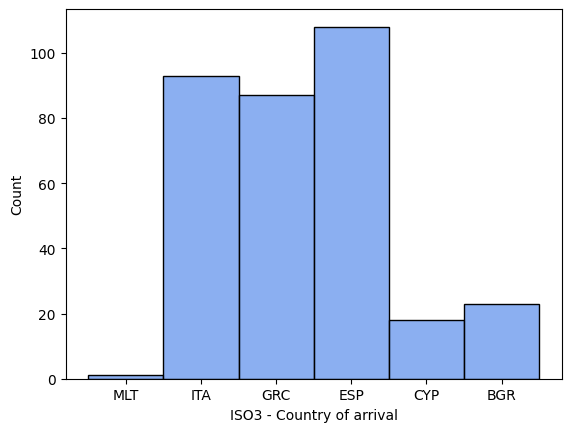

In [43]:
sns.histplot(im1_3['ISO3 - Country of arrival'], bins = 25, color = 'cornflowerblue', edgecolor = 'black');

In [44]:
im1_3['Date'] = pd.to_datetime(im1_3['Date'], errors='coerce')

print(im1_3['Date'].dtype)
print(im1_3['Date'].isna().sum())

datetime64[ns]
0


In [74]:
# Here I do with fourth (I skip third) column 'Others_Countries_CoO' from my first dataset
# 'im1' - is for first datasets, '_4' is for fourth column

# im1_4 = pd.read_excel('/content/DTM Europe_Q1_2026_Dataset.xlsx', sheet_name='Others_Countries_CoO')

In [75]:
im1_4.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 439 entries, 0 to 438
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Date                       439 non-null    datetime64[ns]
 1   Year                       439 non-null    int64         
 2   Month                      439 non-null    int64         
 3   ISO3 - Country of origin   439 non-null    object        
 4   ISO3 - Country of arrival  439 non-null    object        
 5   Route                      439 non-null    object        
 6   Arrivals                   439 non-null    int64         
 7   Source                     439 non-null    object        
dtypes: datetime64[ns](1), int64(3), object(4)
memory usage: 27.6+ KB


In [76]:
im1_4.head()

,Date,Year,Month,ISO3 - Country of origin,ISO3 - Country of arrival,Route,Arrivals,Source
0,2026-01-31,2026,1,AFG,XKX,WBR,1,"Kosovo* Ministry of Internal Affairs, Border P..."
1,2026-01-31,2026,1,DZA,XKX,WBR,21,"Kosovo* Ministry of Internal Affairs, Border P..."
2,2026-01-31,2026,1,EGY,XKX,WBR,15,"Kosovo* Ministry of Internal Affairs, Border P..."
3,2026-01-31,2026,1,JOR,XKX,WBR,1,"Kosovo* Ministry of Internal Affairs, Border P..."
4,2026-01-31,2026,1,LBN,XKX,WBR,1,"Kosovo* Ministry of Internal Affairs, Border P..."


In [77]:
# here I saw which countries the migrants who traveled the Balkan route were from

im1_4['ISO3 - Country of origin'].unique()

array(['AFG', 'DZA', 'EGY', 'JOR', 'LBN', 'MAR', 'NGA', 'PSE', 'SDN',
       'SYR', 'TUN', 'TUR', 'IRN', 'LBY', 'NPL', 'OOO', 'RUS', 'BGD',
       'CHN', 'IND', 'PAK', 'IRQ', 'BLR', 'ERI', 'KAZ', 'UGA', 'UKR',
       'YEM', 'SOM', 'GHA', 'GIN', 'KWT', 'MLI', 'SLE', 'SSD', 'AZE',
       'CIV', 'CMR', 'GEO', 'VNM', 'BRA', 'COG', 'KEN', 'LKA', 'MMR',
       'KGZ', 'GMB', 'MEX', 'MNG', 'NER', 'SEN', 'BDI', 'COD', 'IDN',
       'TZA', 'CUB', 'ETH', 'MDA', 'PHL', 'QAT', 'SAU', 'TKM'],
      dtype=object)

In [49]:
# here I saw which countries the migrants entered by taking the Balkan route

im1_4['ISO3 - Country of arrival'].unique()

array(['XKX', 'SVN', 'ROU', 'MNE', 'MKD', 'HRV', 'BIH', 'ALB'],
      dtype=object)

In [50]:
im1_4.groupby(['Date','ISO3 - Country of arrival', 'Route'])['Arrivals'].sum()

Date        ISO3 - Country of arrival  Route   
2026-01-31  ALB                        WBR           64
            BIH                        WBR          732
            HRV                        EU Other     622
            MKD                        WBR          250
            MNE                        WBR          203
            ROU                        EU Other      50
            SVN                        EU Other    1721
            XKX                        WBR           62
2026-02-28  ALB                        WBR          237
            BIH                        WBR         1119
            HRV                        EU Other     559
            MKD                        WBR          634
            MNE                        WBR          405
            ROU                        EU Other      12
            SVN                        EU Other    1856
            XKX                        WBR           73
2026-03-31  ALB                        WBR          125
            BIH                        WBR         1723
            HRV                        EU Other     631
            MKD                        WBR          549
            MNE                        WBR          453
            ROU                        EU Other       3
            SVN                        EU Other    2345
            XKX                        WBR           95
Name: Arrivals, dtype: int64

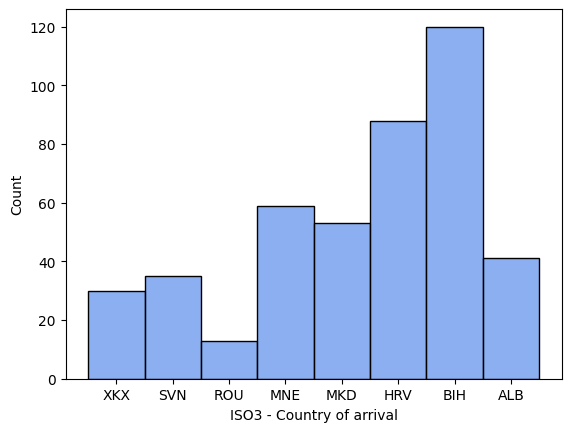

In [51]:
sns.histplot(im1_4['ISO3 - Country of arrival'], bins = 25, color = 'cornflowerblue', edgecolor = 'black');

In [83]:
# Create a copy of the second dataset
df_mne = im1_2.copy()

# Convert Date column to datetime
df_mne['Date'] = pd.to_datetime(
    df_mne['Date'],
    errors='coerce'
)

# Remove rows without valid dates
df_mne = df_mne.dropna(subset=['Date'])

# Filter Montenegro
df_mne = df_mne[
    df_mne['ISO3 - Country of arrival'] == 'MNE'
].copy()

# Create monthly date
df_mne['Month'] = (
    df_mne['Date']
    .dt.to_period('M')
    .dt.to_timestamp()
)

# Group arrivals by month
mne_monthly = (
    df_mne.groupby('Month')['Arrivals']
    .sum()
    .sort_index()
)

# Display results
print(mne_monthly)
print("Number of months:", len(mne_monthly))

Month
2016-01-01      81
2016-02-01      15
2016-03-01       3
2016-04-01       9
2016-05-01       2
2016-06-01       6
2016-07-01       9
2016-08-01      31
2016-09-01       9
2016-10-01      28
2016-11-01      45
2016-12-01      70
2017-01-01      41
2017-02-01      36
2017-03-01      39
2017-04-01      14
2017-05-01      23
2017-06-01      34
2017-07-01      39
2017-08-01     179
2017-09-01      97
2017-10-01      66
2017-11-01     101
2017-12-01     138
2018-01-01      15
2018-02-01      61
2018-03-01     320
2018-04-01     469
2018-05-01     583
2018-06-01     558
2018-07-01     499
2018-08-01     520
2018-09-01     387
2018-10-01     659
2018-11-01     329
2018-12-01     245
2019-01-01     256
2019-02-01     503
2019-03-01     711
2019-04-01     732
2019-05-01     658
2019-06-01     609
2019-07-01     703
2019-08-01     833
2019-09-01     878
2019-10-01    1220
2019-11-01     961
2019-12-01     631
2020-01-01     536
2020-02-01     497
2020-03-01     221
2020-04-01      54
2020-0

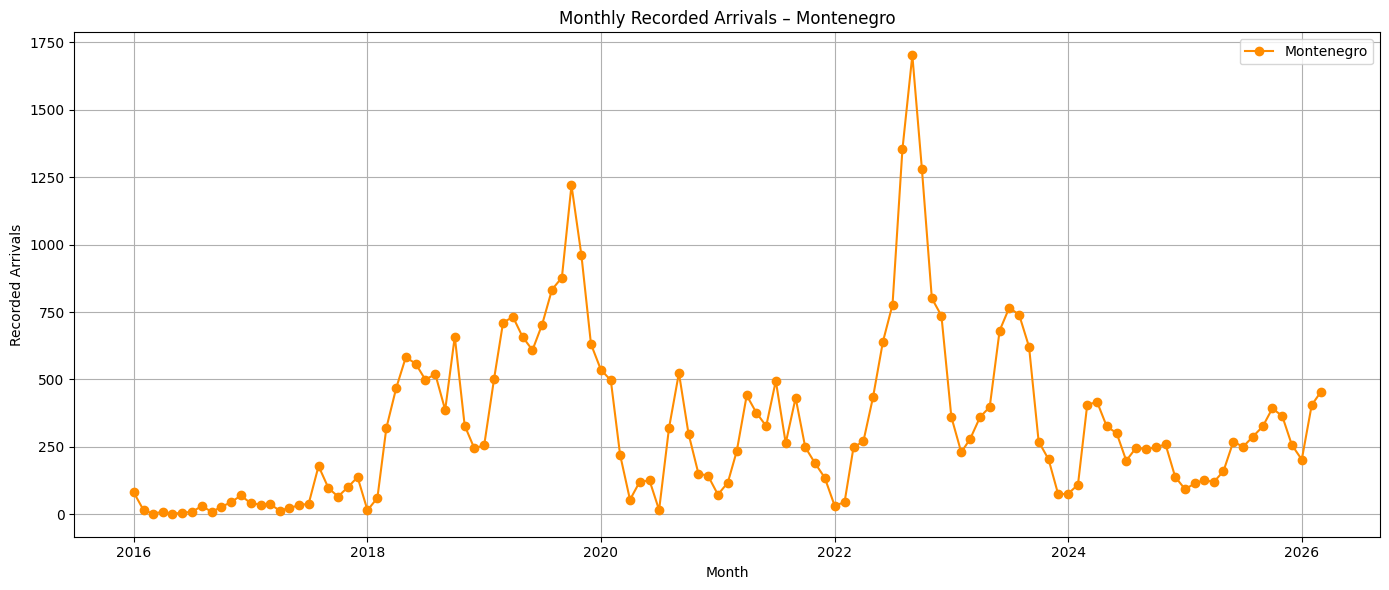

In [84]:
plt.figure(figsize=(14, 6))

plt.plot(
    mne_monthly.index,
    mne_monthly.values,
    marker='o',
    label='Montenegro',
    color='darkorange'
)

plt.title('Monthly Recorded Arrivals – Montenegro')
plt.xlabel('Month')
plt.ylabel('Recorded Arrivals')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [86]:
print("First month:", mne_monthly.index.min())
print("Last month:", mne_monthly.index.max())
print("Total recorded arrivals:", mne_monthly.sum())

First month: 2016-01-01 00:00:00
Last month: 2026-03-01 00:00:00
Total recorded arrivals: 40897


In [87]:
mne_monthly.head()

,Arrivals
Month,
2016-01-01,81
2016-02-01,15
2016-03-01,3
2016-04-01,9
2016-05-01,2


In [88]:
mne_monthly.tail()

,Arrivals
Month,
2025-11-01,364
2025-12-01,257
2026-01-01,203
2026-02-01,405
2026-03-01,453


<Axes: xlabel='Month'>

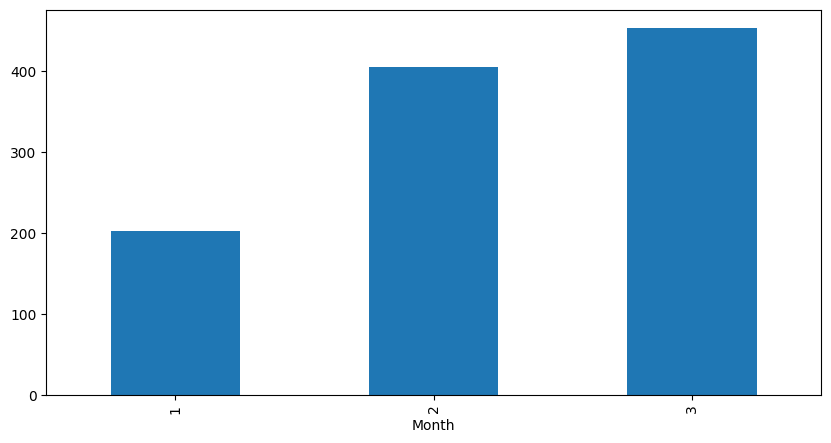

In [53]:
# This bar shows the number of migrants who entered Montenegro in January, February and March 2026.
im1_4[(im1_4['ISO3 - Country of arrival']=='MNE')].groupby('Month')['Arrivals'].sum().plot(kind='bar',x='Month', y='Arrivals', figsize=(10,5))


In [54]:
# Here I do with fifth column 'All_Migrant_Presence' from my first dataset
# 'im1' im- is for first datasets, '_5' is for fifth column
im1_5 = pd.read_excel('/content/DTM Europe_Q1_2026_Dataset.xlsx', sheet_name= 'All_Migrant_Presence')

In [55]:
im1_5.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 147 entries, 0 to 146
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Date                 147 non-null    datetime64[ns]
 1   Year                 147 non-null    int64         
 2   Month                147 non-null    int64         
 3   Week                 147 non-null    int64         
 4   ISO3 - Host country  147 non-null    object        
 5   Individuals present  147 non-null    int64         
dtypes: datetime64[ns](1), int64(4), object(1)
memory usage: 7.0+ KB


In [56]:
im1_5.head()

,Date,Year,Month,Week,ISO3 - Host country,Individuals present
0,2026-01-04,2026,1,2,ALB,5
1,2026-01-11,2026,1,3,ALB,5
2,2026-01-18,2026,1,4,ALB,5
3,2026-01-25,2026,1,5,ALB,5
4,2026-02-01,2026,1,6,ALB,20


In [57]:
im1_5['ISO3 - Host country'].unique()

array(['ALB', 'BGR', 'BIH', 'CYP', 'GRC', 'ITA', 'MKD', 'MNE', 'ROU',
       'SRB', 'SVN', 'XKX'], dtype=object)

In [58]:
im1_5.groupby(['Year', 'ISO3 - Host country'])['Individuals present'].sum()

Year  ISO3 - Host country
2026  ALB                        600
      BGR                       5401
      BIH                      15058
      CYP                       8216
      GRC                     254563
      ITA                    1664444
      MKD                        748
      MNE                        669
      ROU                       2720
      SRB                       2563
      SVN                      11080
      XKX                        378
Name: Individuals present, dtype: int64

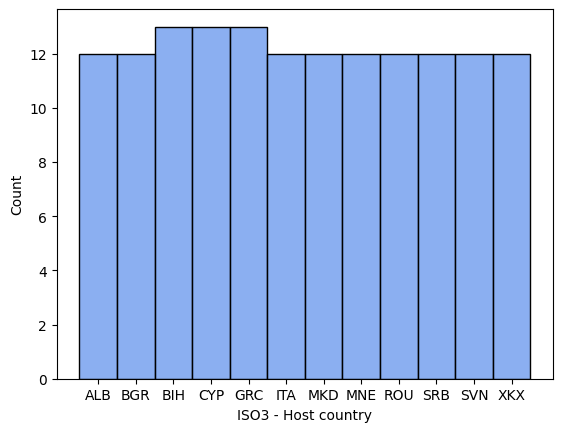

In [59]:
sns.histplot(im1_5['ISO3 - Host country'], bins = 25, color = 'cornflowerblue', edgecolor = 'black');

In [60]:
# the flow of migrants to Montenegro in 2026 is shown
im1_5[im1_5['ISO3 - Host country'] == 'MNE']

,Date,Year,Month,Week,ISO3 - Host country,Individuals present
87,2026-01-04,2026,1,2,MNE,79
88,2026-01-11,2026,1,3,MNE,60
89,2026-01-18,2026,1,4,MNE,54
90,2026-01-25,2026,1,5,MNE,44
91,2026-02-01,2026,1,6,MNE,51
92,2026-02-08,2026,2,7,MNE,68
93,2026-02-15,2026,2,8,MNE,62
94,2026-02-22,2026,2,9,MNE,73
95,2026-03-01,2026,2,10,MNE,46
96,2026-03-08,2026,3,11,MNE,46


Here I am done with the primary review of my first data set, which has a total of **2,780 rows in 5 sheets.**

In [61]:
# Here I am read and searching my second exel datasets 'im2', wich have 9 but I will fokus on 5 main sheets
# below I will explore each of them in depth
# im2 = pd.read_excel('/content/DTM Europe_Q2_2026_Dataset.xlsx')

In [62]:
# xls2 = pd.ExcelFile('/content/DTM Europe_Q2_2026_Dataset.xlsx')
# xls2.sheet_names

In [63]:
# for i, sheet in enumerate(xls2.sheet_names, start=1):
# globals()['im_%s'%str(i)] = pd.read_excel('/content/DTM Europe_Q2_2026_Dataset.xlsx', sheet_name=sheet)

In [64]:
# im2.info()

In [65]:
# im2.head()